# battery_model.ipynb  (Sarvesh)
Battery location, rating, SOC model (15-min), validation of CHARGE / IDLE / DISCHARGE, and insertion into the SimBench net as a real `pandapower.storage` element.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")                       # folder containing sarvesh_lib.py
import simbench as sb, pandapower as pp
from sarvesh_lib import *

net = sb.get_simbench_net("1-MVLV-urban-all-0-sw")
profiles = sb.get_absolute_values(net, profiles_instead_of_study_cases=True)
print(len(net.bus), "buses |", len(net.storage), "storage units (should be 0 before we add ours)")

10458 buses | 0 storage units (should be 0 before we add ours)


## 1. Battery design

In [2]:
cfg = BatteryConfig(
    bus=-1,              # -1 => auto-select 10 kV substation bus (change if you prefer a feeder bus)
    p_max_mw=5.0, e_cap_mwh=20.0,
    soc_min=0.10, soc_max=0.90, soc_init=0.50,
    eta_c=0.95, eta_d=0.95)
sidx = add_battery(net, cfg)
print("Battery bus:", cfg.bus, "| vn_kv =", net.bus.at[cfg.bus, "vn_kv"])
print(net.storage[["bus","p_mw","max_e_mwh","min_e_mwh","soc_percent"]])

Battery bus: 30944 | vn_kv = 10.0
     bus  p_mw  max_e_mwh  min_e_mwh  soc_percent
0  30944   0.0       20.0        2.0         50.0


## 2. SOC model validation (pure model tests)

In [3]:
# Test A: charge at full power for 24 h -> must saturate at SOC_max and never exceed power limit
p, E = simulate_schedule(np.full(T, cfg.p_max_mw), cfg)
assert E.max() <= cfg.e_max + 1e-9 and p.max() <= cfg.p_max_mw + 1e-9
print("A  charge-only : final SOC = %.1f %%" % (E[0,-1]/cfg.e_cap_mwh*100))

# Test B: discharge at full power -> must stop at SOC_min
p, E = simulate_schedule(np.full(T, -cfg.p_max_mw), cfg)
assert E.min() >= cfg.e_min - 1e-9
print("B  discharge   : final SOC = %.1f %%" % (E[0,-1]/cfg.e_cap_mwh*100))

# Test C: idle -> SOC unchanged
p, E = simulate_schedule(np.zeros(T), cfg)
assert np.allclose(E, cfg.e_init); print("C  idle        : SOC constant OK")

# Test D: round-trip efficiency = eta_c * eta_d
p_in = np.r_[np.full(8, 2.0), np.zeros(T-8)]                 # 2 MW for 2 h = 4 MWh drawn from grid
_, E1 = simulate_schedule(p_in, cfg)
stored = E1[0, 8] - cfg.e_init                               # MWh actually stored
delivered = stored * cfg.eta_d                               # MWh that can be sent back to the grid
print("D  round trip  : %.4f (expected %.4f)" % (delivered / 4.0, cfg.eta_c * cfg.eta_d))

# Test E: an infeasible request is repaired
print("E  request 5 MW at SOC_max -> allowed %.2f MW" % feasible_power(cfg.e_max, 5.0, cfg))

A  charge-only : final SOC = 90.0 %
B  discharge   : final SOC = 10.0 %
C  idle        : SOC constant OK
D  round trip  : 0.9025 (expected 0.9025)
E  request 5 MW at SOC_max -> allowed 0.00 MW


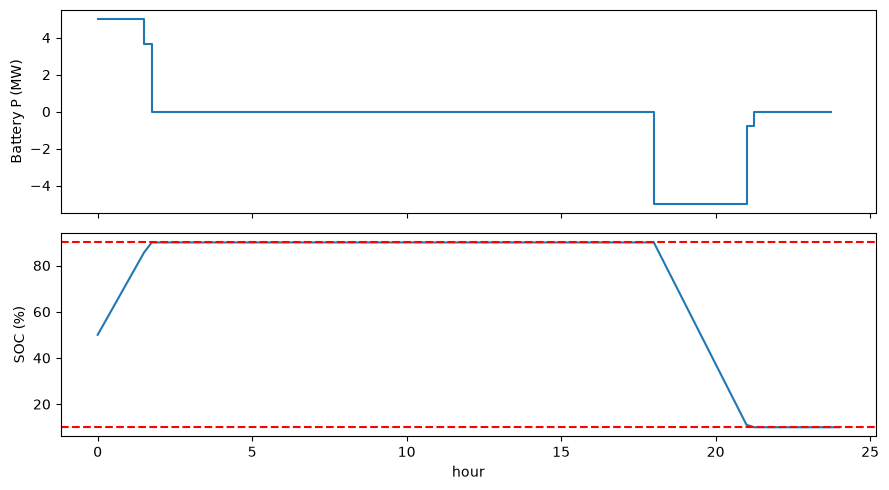

In [4]:
# Plot SOC for a demo schedule: charge 00-04h, idle, discharge 18-22h
demo = np.zeros(T); demo[0:16] = 5; demo[72:88] = -5
p, E = simulate_schedule(demo, cfg)
fig, ax = plt.subplots(2,1, figsize=(9,5), sharex=True)
ax[0].step(np.arange(T)/4, p[0], where="post"); ax[0].set_ylabel("Battery P (MW)")
ax[1].plot(np.arange(T+1)/4, E[0]/cfg.e_cap_mwh*100); ax[1].set_ylabel("SOC (%)"); ax[1].set_xlabel("hour")
ax[1].axhline(cfg.soc_min*100, ls="--", c="r"); ax[1].axhline(cfg.soc_max*100, ls="--", c="r")
plt.tight_layout(); plt.show()

## 3. Check the battery really acts on the power flow (physics check)

In [5]:
step = 33001                                   # 09-12-2016 18:15 (annual peak)
apply_profile_step(net, profiles, step)
res = {}
for label, pb in [("idle", 0.0), ("charge +5 MW", 5.0), ("discharge -5 MW", -5.0)]:
    set_battery_power(net, sidx, pb); run_pf(net); res[label] = grid_metrics(net)
df = pd.DataFrame(res).T[["grid_import_mw","v_min_pu","max_line_loading_pct","max_trafo_loading_pct","line_losses_mw","transformer_losses_mw"]]
display(df)      # grid import should change by about +/- 5 MW
set_battery_power(net, sidx, 0.0)

,grid_import_mw,v_min_pu,max_line_loading_pct,max_trafo_loading_pct,line_losses_mw,transformer_losses_mw
idle,19.359202,0.994604,32.203874,31.378085,0.134484,0.319022
charge +5 MW,24.364318,0.994604,32.203874,31.378085,0.134550,0.324073
discharge -5 MW,14.356526,0.994604,32.203874,31.378085,0.134437,0.316394


In [6]:
import json, os
os.makedirs("output", exist_ok=True)
json.dump(asdict(cfg), open("output/battery_config.json","w"), indent=2)
print("saved output/battery_config.json")

saved output/battery_config.json
